<a href="https://colab.research.google.com/github/Atik1219/CaSRA-Supplier-Disruption-Prediction-Dataset/blob/main/Ablation_Study_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:

!pip -q install xgboost statsmodels

import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import statsmodels.api as sm
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

In [13]:

from google.colab import files
up = files.upload()
df = pd.read_csv(list(up.keys())[0])
df["supplier_code"] = df["supplier"].astype("category").cat.codes
y = df["high_disruption_p"].values
print(df.shape); df.head()

Saving Supplier_Disruption_LogTable_Coded.csv to Supplier_Disruption_LogTable_Coded (1).csv
(600, 12)


,date,supplier,kg_score,Em_Score,twitter_alert,weather_risk,economic_risk,geo_risk,tech_risk,downtime_hours,high_disruption_p,supplier_code
0,1/1/2025,JHH,0.442711,0.552985,1,0,1,0,0,5.1,0.866602,3
1,1/2/2025,JHH,0.599101,0.509835,0,1,0,0,0,7.2,0.847657,3
2,1/3/2025,JHH,0.372080,0.532829,0,0,0,0,0,1.0,0.746924,3
3,1/4/2025,JHH,1.167822,0.571556,0,0,0,0,0,1.8,0.960245,3
4,1/5/2025,JHH,0.071730,0.591891,1,1,0,0,0,7.7,0.752698,3


In [14]:

KG, SEM = ["kg_score"], ["Em_Score"]
FLAGS = ["twitter_alert", "weather_risk", "economic_risk", "geo_risk", "tech_risk"]
DT, SUP = ["downtime_hours"], ["supplier_code"]
FULL = SUP + KG + SEM + FLAGS + DT          # 9 input features (Table 4)

def drop(*groups):
    rm = sum(groups, [])
    return [f for f in FULL if f not in rm]

configs = {
    "A0 Full model":                  FULL,
    "A1 w/o KG score":                drop(KG),
    "A2 w/o Semantic score":          drop(SEM),
    "A3 w/o KG + Semantic":           drop(KG, SEM),
    "A4 w/o risk flags (r1-r5)":      drop(FLAGS),
    "A5 w/o downtime":                drop(DT),
    "A6 KG + Semantic only":          KG + SEM,
    "A7 w/o supplier ID":             drop(SUP),
}
for f in FLAGS:
    configs[f"LOO w/o {f}"] = drop([f])
for k, v in configs.items():
    print(f"{k:32s} {len(v)} features")

A0 Full model                    9 features
A1 w/o KG score                  8 features
A2 w/o Semantic score            8 features
A3 w/o KG + Semantic             7 features
A4 w/o risk flags (r1-r5)        4 features
A5 w/o downtime                  8 features
A6 KG + Semantic only            2 features
A7 w/o supplier ID               8 features
LOO w/o twitter_alert            8 features
LOO w/o weather_risk             8 features
LOO w/o economic_risk            8 features
LOO w/o geo_risk                 8 features
LOO w/o tech_risk                8 features


In [15]:

class FracLogit:
    """Logistic regression for a probability target (Bernoulli likelihood, MLE)."""
    def fit(self, X, y):
        self.m = sm.GLM(y, sm.add_constant(X, has_constant="add"),
                        family=sm.families.Binomial()).fit()
        return self
    def predict(self, X):
        return self.m.predict(sm.add_constant(X, has_constant="add"))

def make_models():
    return {
        "Logistic Regression": FracLogit(),
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1,
                                 max_depth=3, min_samples_leaf=1, min_samples_split=2,
                                 random_state=42),
        "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5,
                                objective="reg:logistic", reg_alpha=0, reg_lambda=1,
                                min_child_weight=1, subsample=1, colsample_bytree=1,
                                random_state=65, verbosity=0),
    }

def metrics(yt, yp, p):
    n, r2 = len(yt), r2_score(yt, yp)
    return dict(MAE=mean_absolute_error(yt, yp), MSE=mean_squared_error(yt, yp),
                R2=r2, AdjR2=1 - (1 - r2) * (n - 1) / (n - p - 1))

In [16]:

N_SEEDS = 5
rows = []
for cname, feats in configs.items():
    X = df[feats].values.astype(float)
    p = len(feats)

    # (a) single 80/20 split
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
    for mname, m in make_models().items():
        m.fit(Xtr, ytr)
        rows.append(dict(protocol="80/20", config=cname, model=mname,
                         **metrics(yte, np.clip(m.predict(Xte), 0, 1), p)))

    # (b) repeated k-fold CV
    for mname in make_models():
        sc = []
        for seed in range(N_SEEDS):
            for tr, te in KFold(5, shuffle=True, random_state=seed).split(X):
                m = make_models()[mname].fit(X[tr], y[tr])
                sc.append(metrics(y[te], np.clip(m.predict(X[te]), 0, 1), p))
        s = pd.DataFrame(sc)
        rows.append(dict(protocol="CV", config=cname, model=mname,
                         MAE=s.MAE.mean(), MSE=s.MSE.mean(), R2=s.R2.mean(),
                         AdjR2=s.AdjR2.mean(), R2_sd=s.R2.std()))
    print("done:", cname)

res = pd.DataFrame(rows)
order = list(configs.keys())
models_order = ["Logistic Regression", "Random Forest", "Gradient Boosting", "XGBoost"]

done: A0 Full model
done: A1 w/o KG score
done: A2 w/o Semantic score
done: A3 w/o KG + Semantic
done: A4 w/o risk flags (r1-r5)
done: A5 w/o downtime
done: A6 KG + Semantic only
done: A7 w/o supplier ID
done: LOO w/o twitter_alert
done: LOO w/o weather_risk
done: LOO w/o economic_risk
done: LOO w/o geo_risk
done: LOO w/o tech_risk


In [17]:
# 6. Summary tables
def table(protocol, metric):
    t = res[res.protocol == protocol].pivot(index="config", columns="model", values=metric)
    return t.loc[order, models_order]

for proto in ["CV", "80/20"]:
    print(f"\n===== R² ({proto}) =====");  display(table(proto, "R2").round(3))
    print(f"===== MAE ({proto}) =====");   display(table(proto, "MAE").round(4))

# % change in R² vs full model (CV)
r2 = table("CV", "R2")
delta = ((r2 - r2.loc["A0 Full model"]) / r2.loc["A0 Full model"] * 100).round(2)
print("\n===== ΔR² (%) vs full model (CV) =====");  display(delta)


===== R² (CV) =====


model,Logistic Regression,Random Forest,Gradient Boosting,XGBoost
config,,,,
A0 Full model,0.999,0.981,0.991,0.992
A1 w/o KG score,0.727,0.666,0.706,0.672
A2 w/o Semantic score,0.675,0.926,0.959,0.963
A3 w/o KG + Semantic,0.414,0.609,0.677,0.661
A4 w/o risk flags (r1-r5),0.983,0.970,0.972,0.971
A5 w/o downtime,0.998,0.981,0.990,0.991
A6 KG + Semantic only,0.966,0.956,0.956,0.954
A7 w/o supplier ID,0.999,0.981,0.991,0.992
LOO w/o twitter_alert,0.983,0.969,0.973,0.973


===== MAE (CV) =====


model,Logistic Regression,Random Forest,Gradient Boosting,XGBoost
config,,,,
A0 Full model,0.0011,0.0165,0.0133,0.0120
A1 w/o KG score,0.0772,0.0839,0.0796,0.0831
A2 w/o Semantic score,0.0881,0.0393,0.0290,0.0272
A3 w/o KG + Semantic,0.1159,0.0910,0.0829,0.0845
A4 w/o risk flags (r1-r5),0.0141,0.0204,0.0208,0.0206
A5 w/o downtime,0.0053,0.0167,0.0140,0.0124
A6 KG + Semantic only,0.0201,0.0241,0.0257,0.0260
A7 w/o supplier ID,0.0010,0.0161,0.0132,0.0120
LOO w/o twitter_alert,0.0147,0.0203,0.0206,0.0201



===== R² (80/20) =====


model,Logistic Regression,Random Forest,Gradient Boosting,XGBoost
config,,,,
A0 Full model,0.998,0.985,0.990,0.992
A1 w/o KG score,0.684,0.702,0.708,0.726
A2 w/o Semantic score,0.686,0.936,0.960,0.960
A3 w/o KG + Semantic,0.425,0.692,0.715,0.723
A4 w/o risk flags (r1-r5),0.983,0.975,0.973,0.969
A5 w/o downtime,0.996,0.987,0.988,0.992
A6 KG + Semantic only,0.977,0.969,0.964,0.964
A7 w/o supplier ID,0.998,0.985,0.990,0.992
LOO w/o twitter_alert,0.984,0.974,0.974,0.970


===== MAE (80/20) =====


model,Logistic Regression,Random Forest,Gradient Boosting,XGBoost
config,,,,
A0 Full model,0.0012,0.0147,0.0137,0.0118
A1 w/o KG score,0.0822,0.0831,0.0822,0.0776
A2 w/o Semantic score,0.0867,0.0362,0.0286,0.0260
A3 w/o KG + Semantic,0.1166,0.0864,0.0815,0.0792
A4 w/o risk flags (r1-r5),0.0137,0.0183,0.0204,0.0209
A5 w/o downtime,0.0060,0.0143,0.0149,0.0125
A6 KG + Semantic only,0.0184,0.0212,0.0242,0.0242
A7 w/o supplier ID,0.0011,0.0141,0.0137,0.0119
LOO w/o twitter_alert,0.0146,0.0189,0.0207,0.0209



===== ΔR² (%) vs full model (CV) =====


model,Logistic Regression,Random Forest,Gradient Boosting,XGBoost
config,,,,
A0 Full model,0.00,0.00,0.00,0.00
A1 w/o KG score,-27.22,-32.05,-28.78,-32.30
A2 w/o Semantic score,-32.43,-5.61,-3.23,-2.94
A3 w/o KG + Semantic,-58.61,-37.91,-31.70,-33.37
A4 w/o risk flags (r1-r5),-1.65,-1.13,-1.85,-2.07
A5 w/o downtime,-0.13,0.00,-0.07,-0.05
A6 KG + Semantic only,-3.27,-2.49,-3.55,-3.81
A7 w/o supplier ID,0.00,0.06,0.01,-0.00
LOO w/o twitter_alert,-1.57,-1.15,-1.77,-1.92


In [19]:

x = res[(res.protocol == "CV") & (res.model == "XGBoost")].set_index("config").loc[order]
paper = r2.round(3).copy()
paper.columns = [f"R² {c}" for c in paper.columns]
paper["XGB MAE"]   = x["MAE"].round(4)
paper["XGB MSE"]   = x["MSE"].round(4)
paper["XGB AdjR²"] = x["AdjR2"].round(3)
paper["ΔR² XGB (%)"] = delta["XGBoost"]
display(paper)
paper.to_csv("ablation_table_paper.csv")
res.round(5).to_csv("ablation_results_all.csv", index=False)

,R² Logistic Regression,R² Random Forest,R² Gradient Boosting,R² XGBoost,XGB MAE,XGB MSE,XGB AdjR²,ΔR² XGB (%)
config,,,,,,,,
A0 Full model,0.999,0.981,0.991,0.992,0.0120,0.0003,0.991,0.00
A1 w/o KG score,0.727,0.666,0.706,0.672,0.0831,0.0115,0.648,-32.30
A2 w/o Semantic score,0.675,0.926,0.959,0.963,0.0272,0.0013,0.960,-2.94
A3 w/o KG + Semantic,0.414,0.609,0.677,0.661,0.0845,0.0118,0.640,-33.37
A4 w/o risk flags (r1-r5),0.983,0.970,0.972,0.971,0.0206,0.0010,0.970,-2.07
A5 w/o downtime,0.998,0.981,0.990,0.991,0.0124,0.0003,0.991,-0.05
A6 KG + Semantic only,0.966,0.956,0.956,0.954,0.0260,0.0016,0.953,-3.81
A7 w/o supplier ID,0.999,0.981,0.991,0.992,0.0120,0.0003,0.991,-0.00
LOO w/o twitter_alert,0.983,0.969,0.973,0.973,0.0201,0.0009,0.971,-1.92


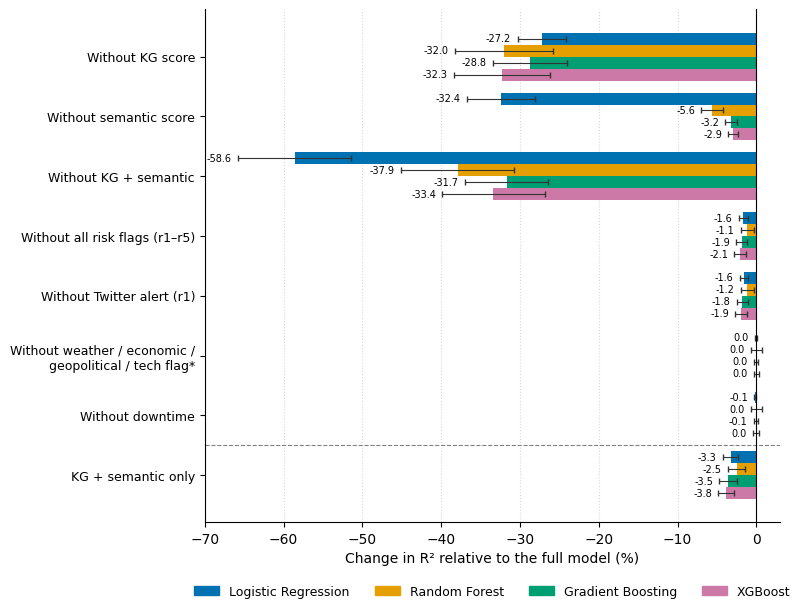

In [20]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

cv = res[res.protocol == "CV"].copy()
full = cv[cv.config == "A0 Full model"].set_index("model")["R2"]
base = cv["model"].map(full)
cv["dR2"] = (cv["R2"] - base) / base * 100
cv["dR2_sd"] = cv["R2_sd"] / base * 100

rows = [
    ("A1 w/o KG score",           "Without KG score"),
    ("A2 w/o Semantic score",     "Without semantic score"),
    ("A3 w/o KG + Semantic",      "Without KG + semantic"),
    ("A4 w/o risk flags (r1-r5)", "Without all risk flags (r1–r5)"),
    ("LOO w/o twitter_alert",     "Without Twitter alert (r1)"),
    ("OTHER_FLAGS",               "Without weather / economic /\ngeopolitical / tech flag*"),
    ("A5 w/o downtime",           "Without downtime"),
    ("A6 KG + Semantic only",     "KG + semantic only"),
]
other = ["LOO w/o weather_risk", "LOO w/o economic_risk", "LOO w/o geo_risk", "LOO w/o tech_risk"]

def get(cfg, model):
    if cfg == "OTHER_FLAGS":   # largest drop among the four flags
        s = cv[(cv.config.isin(other)) & (cv.model == model)].sort_values("dR2").iloc[0]
    else:
        s = cv[(cv.config == cfg) & (cv.model == model)].iloc[0]
    return s.dR2, s.dR2_sd

colors = {"Logistic Regression": "#0072B2", "Random Forest": "#E69F00",
          "Gradient Boosting": "#009E73", "XGBoost": "#CC79A7"}
h = 0.2
fig, ax = plt.subplots(figsize=(8, 6.2))
for i, (cfg, _) in enumerate(rows):
    for j, m in enumerate(models_order):
        v, sd = get(cfg, m)
        yy = i + (j - 1.5) * h
        ax.barh(yy, v, height=h, color=colors[m], xerr=sd,
                error_kw=dict(lw=0.8, capsize=2, ecolor="#333"))
        ax.text(min(v - sd, 0) - 0.8, yy, f"{v:.1f}".replace("-0.0", "0.0"),
                va="center", ha="right", fontsize=7)

ax.axhline(6.5, color="grey", lw=0.8, ls="--")
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([lbl for _, lbl in rows], fontsize=9)
ax.invert_yaxis()
ax.axvline(0, color="k", lw=0.8)
ax.set_xlim(-70, 3)
ax.set_xlabel("Change in R² relative to the full model (%)", fontsize=10)
ax.grid(axis="x", ls=":", alpha=0.5); ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.legend(handles=[Patch(color=colors[m], label=m) for m in models_order],
          loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig("ablation_r2_drop.png", dpi=300, bbox_inches="tight")
plt.savefig("ablation_r2_drop.pdf", bbox_inches="tight")
plt.show()

In [ ]:

f = KG + SEM + FLAGS + DT
z = np.log(df.high_disruption_p / (1 - df.high_disruption_p))
ols = sm.OLS(z, sm.add_constant(df[f])).fit()
print("R² of logit(p) on features:", round(ols.rsquared, 4))
print(ols.params.round(4))

In [ ]:

for fn in ["ablation_table_paper.csv", "ablation_results_all.csv", "ablation_r2_drop.png"]:
    files.download(fn)